In [80]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [81]:
from utils import *

In [82]:
import warnings

def fxn():
    warnings.warn("deprecated", RuntimeWarning)
with warnings.catch_warnings(action="ignore"):
    fxn()

In [83]:
d, n = 50 , 10000
X = np.random.randn( n, d )
y = ( np.sum( X , axis = 1 ) <= 0.5 ).astype(np.int64)

In [84]:
_ = binary_classification(X,y,0.01,30000)

Epochs 1 | Loss 3.1915 | Accuracy 46.02 %
Epochs 101 | Loss 2.8678 | Accuracy 47.9 %
Epochs 201 | Loss 2.5625 | Accuracy 49.96 %
Epochs 301 | Loss 2.2771 | Accuracy 51.93 %
Epochs 401 | Loss 2.0126 | Accuracy 54.18 %
Epochs 501 | Loss 1.7698 | Accuracy 56.46 %
Epochs 601 | Loss 1.5492 | Accuracy 58.87 %
Epochs 701 | Loss 1.3507 | Accuracy 61.32 %
Epochs 801 | Loss 1.1741 | Accuracy 63.62 %
Epochs 901 | Loss 1.0185 | Accuracy 66.1 %
Epochs 1001 | Loss 0.8826 | Accuracy 68.44 %
Epochs 1101 | Loss 0.7654 | Accuracy 70.93 %
Epochs 1201 | Loss 0.6650 | Accuracy 73.31 %
Epochs 1301 | Loss 0.5800 | Accuracy 75.56 %
Epochs 1401 | Loss 0.5084 | Accuracy 77.89 %
Epochs 1501 | Loss 0.4484 | Accuracy 79.88 %
Epochs 1601 | Loss 0.3985 | Accuracy 81.6 %
Epochs 1701 | Loss 0.3571 | Accuracy 83.36 %
Epochs 1801 | Loss 0.3228 | Accuracy 84.8 %
Epochs 1901 | Loss 0.2945 | Accuracy 86.14 %
Epochs 2001 | Loss 0.2712 | Accuracy 87.47 %
Epochs 2101 | Loss 0.2519 | Accuracy 88.85 %
Epochs 2201 | Loss 0.2360 

In [85]:
# Caricamento del dataset
train = MNIST(root="./data", train=True, download=True)
test = MNIST(root="./data", train=False, download=True)

# Conversione in NumPy e normalizzazione
X_train = train.data.numpy().astype(np.float32) / 255.0
X_test = test.data.numpy().astype(np.float32) / 255.0

# 0 = cifra <= 5, 1 = cifra > 5
y_train = (train.targets.numpy() > 5).astype(np.int64)
y_test = (test.targets.numpy() > 5).astype(np.int64)

# Flatten delle immagini
X_train = X_train.reshape(-1, 784)
X_test = X_test.reshape(-1, 784)

In [86]:
idx = np.random.choice( np.arange( X_train.shape[0] ) , size = 10000 , replace=False )
w = binary_classification( X_train[idx,:] , y_train[idx] , 0.1 , 20000 )

Epochs 1 | Loss 2.8269 | Accuracy 56.64 %
Epochs 101 | Loss 1.2773 | Accuracy 69.52 %
Epochs 201 | Loss 0.9867 | Accuracy 73.68 %
Epochs 301 | Loss 0.8497 | Accuracy 75.86 %
Epochs 401 | Loss 0.7672 | Accuracy 77.2 %
Epochs 501 | Loss 0.7102 | Accuracy 78.28 %
Epochs 601 | Loss 0.6673 | Accuracy 78.61 %
Epochs 701 | Loss 0.6333 | Accuracy 79.15 %
Epochs 801 | Loss 0.6054 | Accuracy 79.66 %
Epochs 901 | Loss 0.5821 | Accuracy 80.07 %
Epochs 1001 | Loss 0.5623 | Accuracy 80.42 %
Epochs 1101 | Loss 0.5453 | Accuracy 80.64 %
Epochs 1201 | Loss 0.5304 | Accuracy 80.83 %
Epochs 1301 | Loss 0.5173 | Accuracy 81.02 %
Epochs 1401 | Loss 0.5056 | Accuracy 81.27 %
Epochs 1501 | Loss 0.4951 | Accuracy 81.42 %
Epochs 1601 | Loss 0.4855 | Accuracy 81.6 %
Epochs 1701 | Loss 0.4768 | Accuracy 81.92 %
Epochs 1801 | Loss 0.4688 | Accuracy 82.03 %
Epochs 1901 | Loss 0.4614 | Accuracy 82.29 %
Epochs 2001 | Loss 0.4545 | Accuracy 82.47 %
Epochs 2101 | Loss 0.4481 | Accuracy 82.65 %
Epochs 2201 | Loss 0.442

In [87]:
y_test_pred = classify(w,X_test)
test_accuracy = accuracy(y_test,y_test_pred)
print(f'Test accuracy: {test_accuracy} %')

Test accuracy: 87.5 %


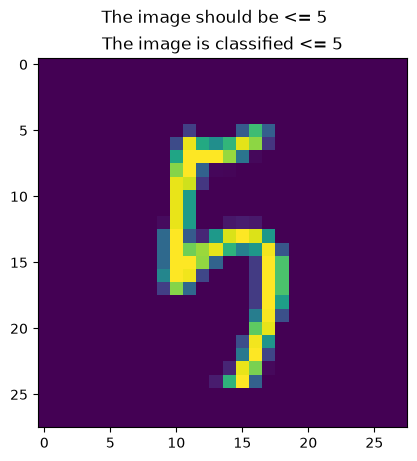

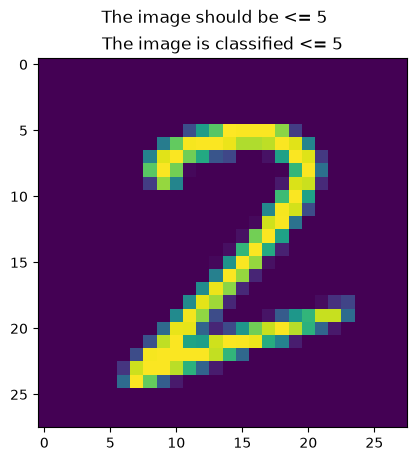

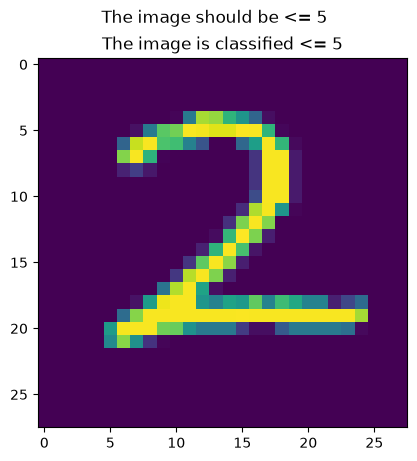

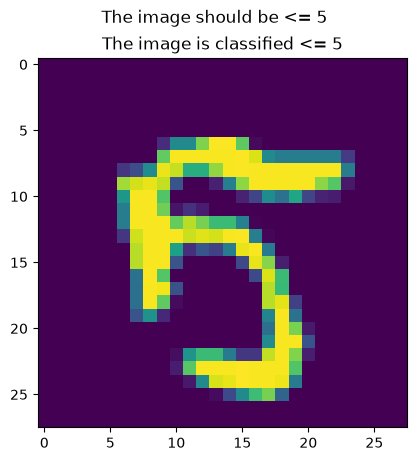

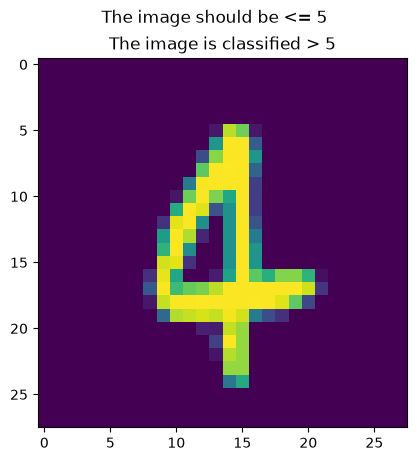

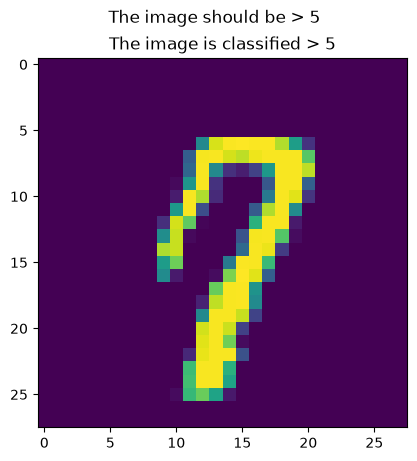

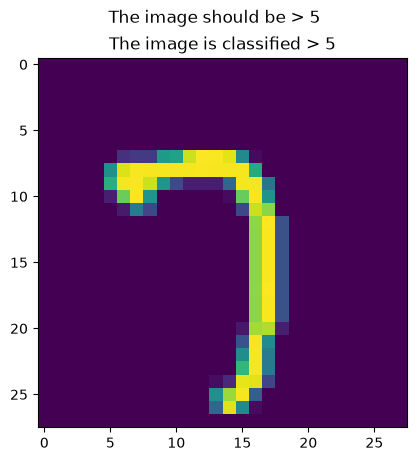

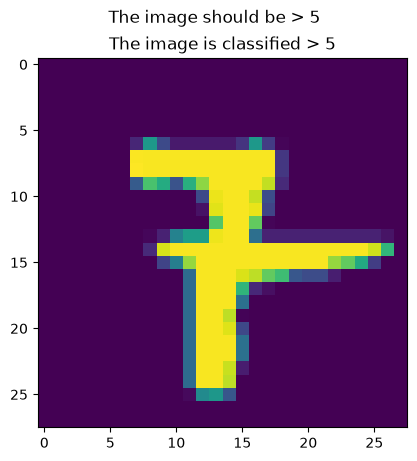

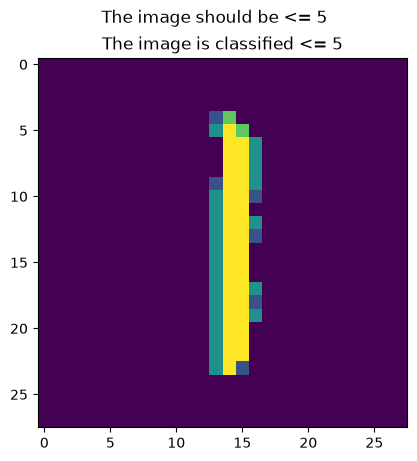

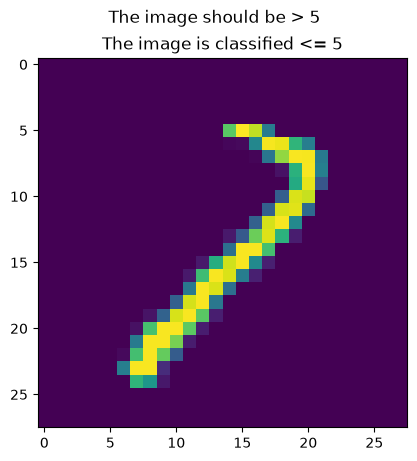

In [88]:
classif = { 0.: '<= 5', 1.:'> 5' }
for k in np.random.choice( np.arange(5000) , size = 10 , replace=False):
    x_plot = X_test[k,:].reshape(28,-1)
    plt.imshow(x_plot)
    plt.suptitle(f'The image should be {classif[ y_test[k] ]}')
    plt.title(f'The image is classified {classif[ y_test_pred[k] ]}')
    plt.show()